# Tadawul Stock Analysis
Downloads Saudi stock prices with `yfinance`, computes returns, volatility, moving averages and drawdowns, and exports clean tables for a Power BI dashboard.

**Data:** Yahoo Finance (Tadawul tickers end in `.SR`). Prices are adjusted for splits and dividends.

## Step 1: Install and import libraries

In [1]:
!pip install -q -U yfinance

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

TRADING_DAYS = 252

## Step 2: Choose the companies and the period

In [3]:
STOCKS = {
    "2222.SR": ("Saudi Aramco",       "Energy"),
    "1120.SR": ("Al Rajhi Bank",      "Banks"),
    "1180.SR": ("Saudi National Bank","Banks"),
    "1150.SR": ("Alinma Bank",        "Banks"),
    "2010.SR": ("SABIC",              "Materials"),
    "1211.SR": ("Maaden",             "Materials"),
    "7010.SR": ("stc",                "Telecom"),
    "2280.SR": ("Almarai",            "Food & Beverages"),
    "4002.SR": ("Mouwasat Medical",   "Healthcare"),
    "2082.SR": ("ACWA Power",         "Utilities"),
}
START = "2023-10-26"   # about 3 years
END = None             # None = up to today

## Step 3: Download the prices

In [4]:
raw = yf.download(list(STOCKS), start=START, end=END, auto_adjust=True, progress=False)
close = raw["Close"].dropna(how="all")
volume = raw["Volume"].reindex(close.index)

missing = [t for t in STOCKS if t not in close.columns or close[t].dropna().empty]
if missing:
    print("No data for:", missing)
close = close.drop(columns=missing, errors="ignore")
print("Days:", len(close), "| Stocks:", close.shape[1])
print("From", close.index.min().date(), "to", close.index.max().date())
close.tail()

Days: 747 | Stocks: 10
From 2023-10-26 to 2026-10-22


Ticker,1120.SR,1150.SR,1180.SR,1211.SR,2010.SR,2082.SR,2222.SR,2280.SR,4002.SR,7010.SR
Date,,,,,,,,,,
2026-10-18,61.150002,23.559999,37.580002,60.299999,45.720001,158.100006,25.799999,42.540001,59.099998,42.299999
2026-10-19,60.549999,23.370001,36.980000,60.349998,45.259998,159.300003,25.799999,42.000000,58.599998,42.099998
2026-10-20,60.150002,23.139999,36.540001,57.500000,44.000000,152.800003,25.480000,41.560001,58.000000,41.279999
2026-10-21,60.200001,21.990000,36.480000,58.799999,45.400002,153.899994,25.580000,41.160000,57.349998,41.360001
2026-10-22,59.799999,21.459999,34.619999,55.900002,43.720001,150.000000,25.400000,41.139999,55.500000,40.820000


## Step 4: Calculate returns, moving averages, volatility and drawdown

In [5]:
frames = []
for t in close.columns:
    s = close[t].dropna()
    d = pd.DataFrame({"Date": s.index, "Ticker": t, "Close": s.values})
    d["Company"], d["Sector"] = STOCKS[t]
    d["Volume"] = volume[t].reindex(s.index).values
    ret = s.pct_change()
    d["Daily Return"] = ret.values
    d["Cumulative Return"] = (s / s.iloc[0] - 1).values           # growth since start
    d["MA50"] = s.rolling(50).mean().values
    d["MA200"] = s.rolling(200).mean().values
    d["Volatility 30D"] = (ret.rolling(30).std() * np.sqrt(TRADING_DAYS)).values  # annualised
    d["Drawdown"] = (s / s.cummax() - 1).values                    # drop from previous peak
    frames.append(d)

prices = pd.concat(frames, ignore_index=True)
prices.tail()

,Date,Ticker,Close,Company,Sector,Volume,Daily Return,Cumulative Return,MA50,MA200,Volatility 30D,Drawdown
7460,2026-10-18,7010.SR,42.299999,stc,Telecom,1104666.0,0.004274,0.445982,43.4780,42.627275,0.081023,-0.054115
7461,2026-10-19,7010.SR,42.099998,stc,Telecom,1862711.0,-0.004728,0.439145,43.4484,42.631299,0.081574,-0.058587
7462,2026-10-20,7010.SR,41.279999,stc,Telecom,2907544.0,-0.019477,0.411114,43.4040,42.633053,0.096994,-0.076923
7463,2026-10-21,7010.SR,41.360001,stc,Telecom,2468096.0,0.001938,0.413849,43.3612,42.634917,0.097033,-0.075134
7464,2026-10-22,7010.SR,40.820000,stc,Telecom,3515179.0,-0.013056,0.395389,43.3056,42.633697,0.100179,-0.087209


## Step 5: Summary table per stock

In [6]:
rows = []
for t, g in prices.groupby("Ticker"):
    g = g.dropna(subset=["Daily Return"])
    years = (g["Date"].iloc[-1] - g["Date"].iloc[0]).days / 365.25
    total = g["Cumulative Return"].iloc[-1]
    ann_ret = (1 + total) ** (1 / years) - 1
    ann_vol = g["Daily Return"].std() * np.sqrt(TRADING_DAYS)
    rows.append({
        "Ticker": t, "Company": g["Company"].iloc[0], "Sector": g["Sector"].iloc[0],
        "Total Return": total, "Annualised Return": ann_ret,
        "Annualised Volatility": ann_vol,
        "Return / Risk": ann_ret / ann_vol,        # simple Sharpe-style ratio, risk-free rate = 0
        "Max Drawdown": g["Drawdown"].min(),
    })
summary = pd.DataFrame(rows).sort_values("Total Return", ascending=False).reset_index(drop=True)
summary.style.format({c: "{:.1%}" for c in ["Total Return", "Annualised Return",
                                            "Annualised Volatility", "Max Drawdown"]} | {"Return / Risk": "{:.2f}"})

,Ticker,Company,Sector,Total Return,Annualised Return,Annualised Volatility,Return / Risk,Max Drawdown
0,1120.SR,Al Rajhi Bank,Banks,52.4%,15.2%,21.1%,0.72,-15.5%
1,1211.SR,Maaden,Materials,51.1%,14.8%,32.1%,0.46,-29.7%
2,7010.SR,stc,Telecom,39.5%,11.8%,16.0%,0.74,-11.1%
3,1180.SR,Saudi National Bank,Banks,28.1%,8.7%,23.8%,0.36,-23.0%
4,1150.SR,Alinma Bank,Banks,10.2%,3.3%,20.6%,0.16,-28.2%
5,2222.SR,Saudi Aramco,Energy,-9.3%,-3.2%,13.4%,-0.24,-23.8%
6,2280.SR,Almarai,Food & Beverages,-18.7%,-6.7%,22.1%,-0.30,-34.6%
7,2082.SR,ACWA Power,Utilities,-30.5%,-11.5%,39.7%,-0.29,-69.8%
8,2010.SR,SABIC,Materials,-34.4%,-13.2%,20.8%,-0.63,-44.2%
9,4002.SR,Mouwasat Medical,Healthcare,-35.0%,-13.4%,27.2%,-0.49,-57.4%


## Step 6: Correlation between stocks

/tmp/ipykernel_7095/2833450321.py:1: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  daily = close.pct_change().dropna(how="all")


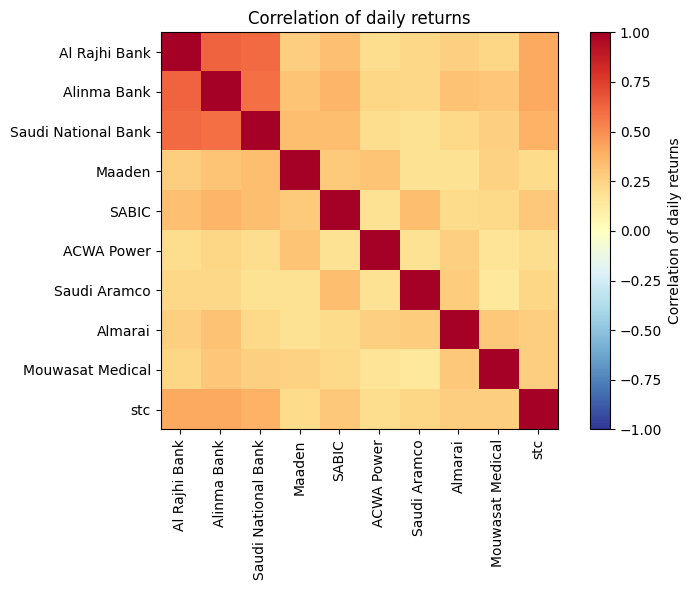

In [7]:
daily = close.pct_change().dropna(how="all")
daily.columns = [STOCKS[c][0] for c in daily.columns]
corr = daily.corr()

plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="RdYlBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
plt.colorbar(label="Correlation of daily returns")
plt.title("Correlation of daily returns")
plt.tight_layout()
plt.show()

## Step 7: Quick charts

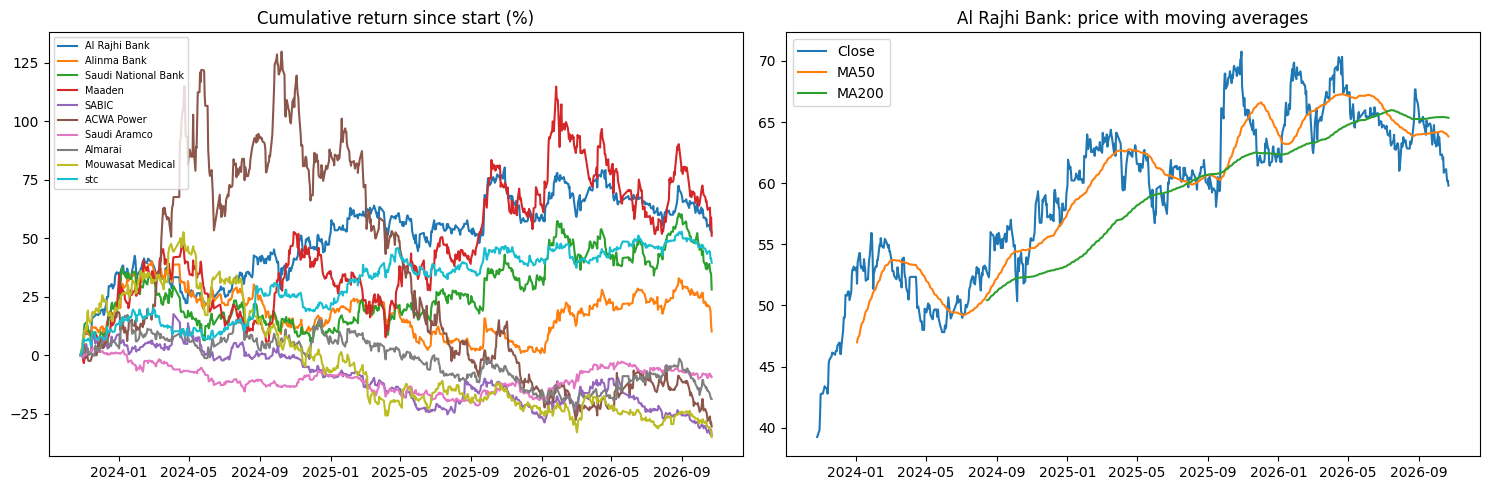

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

for t, g in prices.groupby("Ticker"):
    ax[0].plot(g["Date"], g["Cumulative Return"] * 100, label=g["Company"].iloc[0])
ax[0].set_title("Cumulative return since start (%)")
ax[0].legend(fontsize=7)

pick = summary.iloc[0]["Ticker"]
g = prices[prices["Ticker"] == pick]
ax[1].plot(g["Date"], g["Close"], label="Close")
ax[1].plot(g["Date"], g["MA50"], label="MA50")
ax[1].plot(g["Date"], g["MA200"], label="MA200")
ax[1].set_title(f"{g['Company'].iloc[0]}: price with moving averages")
ax[1].legend()
plt.tight_layout()
plt.show()

## Step 8: Export the tables for Power BI

In [9]:
corr_long = corr.reset_index().melt(id_vars="index", var_name="Stock B", value_name="Correlation")
corr_long = corr_long.rename(columns={"index": "Stock A"})

prices.to_csv("tadawul_prices.csv", index=False)
summary.to_csv("tadawul_summary.csv", index=False)
corr_long.to_csv("tadawul_correlation.csv", index=False)

from google.colab import files
for f in ["tadawul_prices.csv", "tadawul_summary.csv", "tadawul_correlation.csv"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>